
# 02425 Diffusion and stochastich differential equations


## WEEK 6: Itô calculus and SDE’

### Using Itō’s lemma to verify of solution

In [46]:
import numpy as np
import random
from numpy import random
from matplotlib import pyplot as plt
import scipy.stats as stats


### Exercise 1

We are interested in verifying that

$$
Y_t = \sinh(B_t)
$$

satisfies the following Itô SDE

$$
dY_t
=
\frac{1}{2}Y_t\,dt
+
\sqrt{1+Y_t^2}\,dB_t.
$$

We can use Itô's lemma. Let

$$
h(x)=\sinh(x),
$$

such that

$$
Y_t=h(B_t).
$$

The first and second derivatives are given as

$$
h'(x)=\cosh(x),
$$

and

$$
h''(x)=\sinh(x).
$$

By Itô's lemma,

$$
dY_t
=
h'(B_t)dB_t
+
\frac{1}{2}h''(B_t)(dB_t)^2.
$$

Since

$$
(dB_t)^2=dt,
$$

we get

$$
dY_t
=
\cosh(B_t)dB_t
+
\frac{1}{2}\sinh(B_t)dt.
$$

Since

$$
Y_t=\sinh(B_t),
$$

we have

$$
\sinh(B_t)=Y_t.
$$

Furthermore, using the identity

$$
\cosh^2(x)-\sinh^2(x)=1,
$$

we get

$$
\cosh(B_t)
=
\sqrt{1+\sinh^2(B_t)}
=
\sqrt{1+Y_t^2}.
$$

Therefore

$$
dY_t
=
\frac{1}{2}Y_t\,dt
+
\sqrt{1+Y_t^2}\,dB_t.
$$

Thus we have verified that $Y_t=\sinh(B_t)$ satisfies the given Itô SDE.

### Stochastic logistic growth

### Exercise 2

We have the Itô SDE

$$
dX_t
=
\frac{1}{2}X_t\,dt
+
\sqrt{1+X_t^2}\,dB_t.
$$

We are interested in finding a Lamperti transformation

$$
Y_t=h(X_t)
$$

such that the transformed process has additive noise.

For an Itô SDE of the form

$$
dX_t=f(X_t)\,dt+g(X_t)\,dB_t,
$$

the Lamperti transformation is defined as

$$
h(x)
=
\int^x \frac{1}{g(v)}\,dv.
$$

In our case,

$$
g(x)=\sqrt{1+x^2}.
$$

Therefore,

$$
h(x)
=
\int^x \frac{1}{\sqrt{1+v^2}}\,dv.
$$

This gives

$$
h(x)
=
\operatorname{arsinh}(x).
$$

Hence,

$$
Y_t
=
\operatorname{arsinh}(X_t).
$$

We have

$$
h'(x)
=
\frac{1}{\sqrt{1+x^2}}
$$

and

$$
h''(x)
=
-\frac{x}{(1+x^2)^{3/2}}.
$$

By Itô's lemma,

$$
dY_t
=
h'(X_t)dX_t
+
\frac{1}{2}h''(X_t)g^2(X_t)\,dt.
$$

Substituting the expressions for $h'(X_t)$, $h''(X_t)$ and $g(X_t)$ gives

$$
dY_t
=
\frac{1}{\sqrt{1+X_t^2}}
\left(
\frac{1}{2}X_t\,dt
+
\sqrt{1+X_t^2}\,dB_t
\right)
+
\frac{1}{2}
\left(
-\frac{X_t}{(1+X_t^2)^{3/2}}
\right)
(1+X_t^2)\,dt.
$$

Therefore,

$$
dY_t
=
\frac{X_t}{2\sqrt{1+X_t^2}}\,dt
+
dB_t
-
\frac{X_t}{2\sqrt{1+X_t^2}}\,dt.
$$

Thus,

$$
dY_t=dB_t.
$$

Hence, the Lamperti transformed process is

$$
Y_t=\operatorname{arsinh}(X_t),
$$

and the transformed Itô equation has additive noise.

### Numerical analysis with the Euler-Maruyama metho

### Exercise 3

In [47]:
def Brownian(partition):

    BrownianMotion = np.array([])

    for i in range(len(partition)):

        if partition[i] == 0:
            BrownianMotion = np.append(BrownianMotion, 0)
        if partition[i] != 0:
            BrownianMotion = np.append(BrownianMotion, random.normal(loc=BrownianMotion[-1], scale=np.sqrt(partition[i]-partition[i-1])))

    return BrownianMotion



In [48]:
lmda = 1/2
gamma = 1
chsi = 2

T = 100
dt = 0.01
x = chsi



f = lambda x: lmda * (chsi - x)
g = lambda x: gamma*np.sqrt(np.abs(x))


sigma = 0.2
x = 0.1

partition = np.linspace(0, T, int(T/dt))

Bt = Brownian(partition)

def eulersumL(f,g,T,dt,x):
    N = int(T/dt)
    t = np.linspace(0, T, N)
    X = np.zeros(N)
    X[0] = x


    for i in range(1, N):

        X[i] = X[i-1] + X[i-1]*(1-X[i-1])*dt + sigma*X[i-1]*(Bt[i]-Bt[i-1])
        
    return t, X

t, XL = eulersumL(f, g, T, dt, x)
XL

array([0.1       , 0.10037593, 0.10544476, ..., 1.17405942, 1.17048912,
       1.15814906])

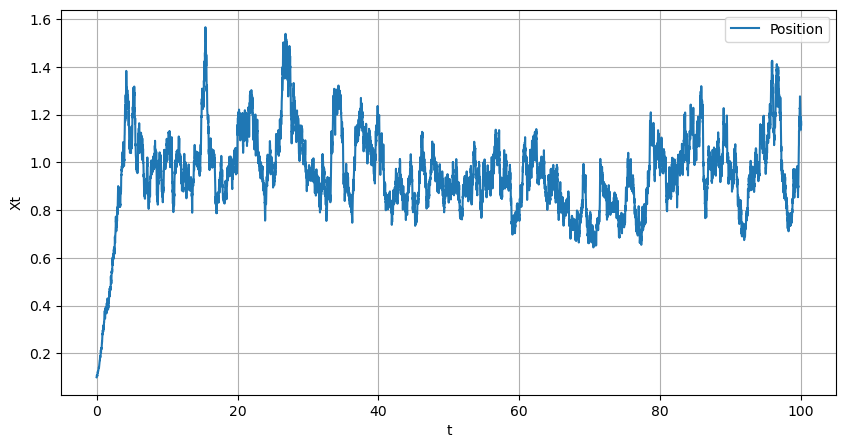

In [49]:
plt.figure(figsize=(10, 5))

plt.plot(t, XL, label="Position")

plt.xlabel("t")
plt.ylabel("Xt")
plt.legend()
plt.grid()

plt.show()

### Exercise 4

In [50]:
lmda = 1/2
gamma = 1
chsi = 2

T = 100
dt = 0.01
x = chsi



f = lambda x: lmda * (chsi - x)
g = lambda x: gamma*np.sqrt(np.abs(x))




sigma = 0.2
x = 0.1


partition = np.linspace(0, T, int(T/dt))

Bt = Brownian(partition)

def eulersumL(f,g,T,dt,x):
    N = int(T/dt)
    t = np.linspace(0, T, N)
    X = np.zeros(N)
    Y = np.zeros(N)
    X[0] = x
    Y[0] = np.arcsinh(x)


    for i in range(1, N):

        X[i] = X[i-1] + X[i-1]*(1-X[i-1])*dt + sigma*X[i-1]*(Bt[i]-Bt[i-1])
        Y[i] = np.arcsinh(X[i])
    return t, X, Y

t, XL, YL = eulersumL(f, g, T, dt, x)

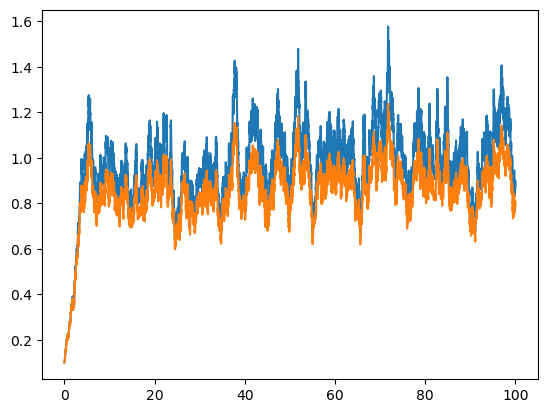

In [51]:
plt.plot(t, XL, label="Xt = Euler-Maruyama")
plt.plot(t, YL, label="Yt = arcsinh(Xt)")

### Exercise 5

In [52]:
steadyX = XL[200:]
steadyY = YL[200:]



print("Mean of X:", np.mean(steadyX))
print("Variance of X:", np.var(steadyX))
print("")
print("Mean of Y:", np.mean(steadyY))
print("Variance of Y:", np.var(steadyY))

Mean of X: 0.9860991015856678
Variance of X: 0.022167209663060725

Mean of Y: 0.8675920595975624
Variance of Y: 0.011359966934636284


Mean and variance in a the noisy harmonic oscillato

### Exercise 6

### Exercise 7